# Nube de palabras — Computación neuromórfica (mejorado)

Objetivo: extraer el texto de https://en.wikipedia.org/wiki/Neuromorphic_computing, limpiar con lematización + filtrado por tipo de palabra (NOUN/PROPN/ADJ), mejorar stopwords y analizar qué caracteriza cada sección con TF-IDF.

**Orden de ejecución:** Paso 1 -> Paso 2 -> Paso 3 -> Paso 4 -> Paso 5 -> Paso 6 -> Paso 7

> Requisito: `spacy` con `en_core_web_sm`. Si no lo descargaste aún: `python -m spacy download en_core_web_sm`


## Paso 1 — Extraer texto de Wikipedia

Descargamos el HTML, removemos elementos irrelevantes (referencias, infobox, navbox, etc.) y separamos el artículo en **texto completo** y **texto por sección** agrupado por encabezados `h2`.


In [1]:
# -*- coding: utf-8 -*-
import requests
from bs4 import BeautifulSoup

URL = 'https://en.wikipedia.org/wiki/Neuromorphic_computing'
HEADERS = {'User-Agent': 'mini-proyecto-nube-de-palabras-mejorado'}

print('Bajando artículo...')
resp = requests.get(URL, headers=HEADERS, timeout=30)
resp.raise_for_status()

soup = BeautifulSoup(resp.text, 'lxml')
contenido = soup.select_one('#mw-content-text')
parser_output = contenido.select_one('.mw-parser-output') or contenido

# Limpiar ruido
for el in parser_output.select('.reference, .mw-references, .reflist, .navbox, .infobox, .sidebar, .toc, .mw-editsection, .noprint, .ambox'):
    el.decompose()

# Texto completo
elementos_full = parser_output.find_all(['p', 'h2', 'h3'])
parrafos_full = [e.get_text(' ', strip=True) for e in elementos_full if e.name in ('p','h2','h3')]
texto_completo = '\n'.join([p for p in parrafos_full if p])
print('Caracteres (texto completo):', len(texto_completo))

# Texto por sección agrupado por h2
secciones = {}
actual = 'Introducción'
buf = []
for e in parser_output.find_all(['p','h2','h3']):
    if e.name == 'h2':
        if buf:
            secciones[actual] = '\n'.join(buf)
        span = e.find('span', class_='mw-headline')
        actual = span.get_text(' ', strip=True) if span else e.get_text(' ', strip=True)
        buf = []
    elif e.name == 'p':
        t = e.get_text(' ', strip=True)
        if t:
            buf.append(t)
    elif e.name == 'h3':
        t = e.get_text(' ', strip=True)
        if t:
            buf.append(t)
if buf:
    secciones[actual] = '\n'.join(buf)

print('Secciones detectadas:', len(secciones))
for k,v in secciones.items():
    print(f' - {k}: {len(v)} caracteres')


Bajando artículo...
Caracteres (texto completo): 5656
Secciones detectadas: 5
 - Introducción: 842 caracteres
 - History: 2615 caracteres
 - Neurological inspiration: 478 caracteres
 - Implementation: 1140 caracteres
 - Ethical considerations: 471 caracteres


## Paso 2 — spaCy: lematización, filtrado por POS y stopwords mejorados

Usamos `spaCy` con `en_core_web_sm`. Nos quedamos únicamente con **sustantivos (NOUN), nombres propios (PROPN) y adjetivos (ADJ)** lematizados.

También ampliamos las stopwords con palabras genéricas del dominio para limpiar aún más el resultado.


In [2]:
# -*- coding: utf-8 -*-
import re
import spacy

try:
    nlp = spacy.load('en_core_web_sm')
    print('spaCy cargado: en_core_web_sm')
except OSError:
    raise OSError("Falta en_core_web_sm. Ejecutá: python -m spacy download en_core_web_sm")

STOP_CUSTOM = set(spacy.lang.en.stop_words.STOP_WORDS)
STOP_CUSTOM.update({
    'use','used','using','uses',
    'based','base',
    'system','systems',
    'model','models','modeling','modelling',
    'approach','approaches',
    'method','methods',
    'process','processes',
    'result','results',
    'show','shows','shown',
    'include','includes','included',
    'provide','provides','provided',
    'different','various',
    'figure','fig','table',
    'example','examples',
    'term','terms',
    'also','however','therefore','thus',
    'first','second','third',
    'one','two','three',
    'new','old','large','small','current','general','specific',
    'time','case','form','type','way','work','order','level'})

POS_OK = {'NOUN', 'PROPN', 'ADJ'}

def limpiar_y_lemmatizar(texto, allowed_pos=POS_OK, min_len=3):
    if not texto or not texto.strip():
        return []
    doc = nlp(texto)
    lemmas = []
    for tok in doc:
        if tok.is_space or tok.is_punct or tok.is_digit:
            continue
        if tok.like_num or tok.like_url or tok.like_email:
            continue
        lemma = tok.lemma_.lower().strip()
        if not lemma or lemma == '-pron-':
            continue
        if len(lemma) < min_len:
            continue
        if lemma in STOP_CUSTOM:
            continue
        if tok.pos_ not in allowed_pos:
            continue
        if not re.match(r'^[a-z][a-z\-]+$', lemma):
            continue
        lemmas.append(lemma)
    return lemmas

print('Listo: limpiar_y_lemmatizar()')


spaCy cargado: en_core_web_sm
Listo: limpiar_y_lemmatizar()


## Paso 3 — Frecuencias con lematización + CSV

Aplicamos el filtrado al **texto completo** y guardamos `frecuencias_palabras_lemas.csv`.


In [3]:
# -*- coding: utf-8 -*-
from collections import Counter
import pandas as pd

lemmas_completo = limpiar_y_lemmatizar(texto_completo)
conteo_lemmas = Counter(lemmas_completo)

df_lemmas = pd.DataFrame(conteo_lemmas.items(), columns=['termino','frecuencia'])
df_lemmas = df_lemmas.sort_values('frecuencia', ascending=False).reset_index(drop=True)

df_lemmas.to_csv('frecuencias_palabras_lemas.csv', index=False)
print('Guardado: frecuencias_palabras_lemas.csv')
print('Términos únicos (NOUN/PROPN/ADJ):', len(df_lemmas))
df_lemmas.head(20)


Guardado: frecuencias_palabras_lemas.csv
Términos únicos (NOUN/PROPN/ADJ): 239


,termino,frecuencia
0,neuromorphic,19
1,neuron,12
2,brain,9
3,neural,7
4,researcher,7
5,chip,7
6,artificial,6
7,memristor,5
8,energy,4
9,recognition,4


## Paso 4 — Nube de palabras global (lematizada + filtrada)

Nube con solo sustantivos, nombres propios y adjetivos lematizados. Mucho más limpia.


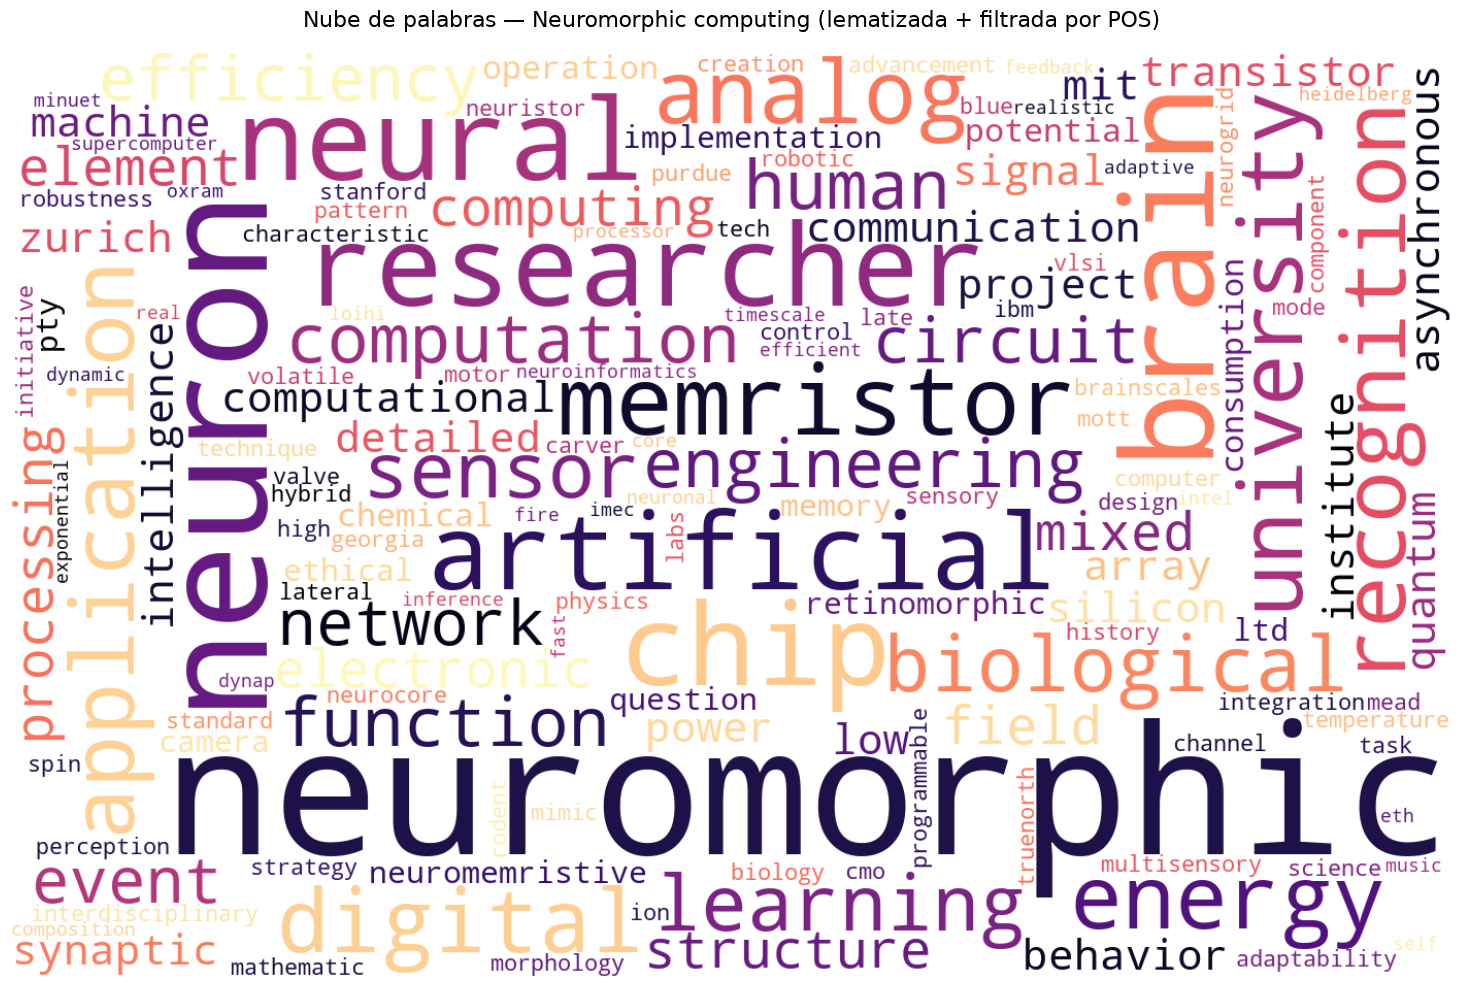

Guardado: nube_de_palabras_lematizada.png


In [4]:
# -*- coding: utf-8 -*-
from wordcloud import WordCloud
import matplotlib.pyplot as plt

wc = WordCloud(width=1400, height=900, background_color='white', colormap='magma', max_words=150, collocations=False)
wc.generate_from_frequencies(dict(conteo_lemmas))

plt.figure(figsize=(16,10))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Nube de palabras — Neuromorphic computing (lematizada + filtrada por POS)', fontsize=16, pad=18)
plt.tight_layout()
plt.savefig('nube_de_palabras_lematizada.png', dpi=220, bbox_inches='tight')
plt.show()
print('Guardado: nube_de_palabras_lematizada.png')


## Paso 5 — Nubes por sección (lematizadas + filtradas)

Aplicamos el mismo criterio por cada sección para ver la diferencia entre ellas.


Guardado: nubes_por_seccion_filtradas/nube_introducción.png
Guardado: nubes_por_seccion_filtradas/nube_history.png
Guardado: nubes_por_seccion_filtradas/nube_neurological_inspiration.png
Guardado: nubes_por_seccion_filtradas/nube_implementation.png
Guardado: nubes_por_seccion_filtradas/nube_ethical_considerations.png


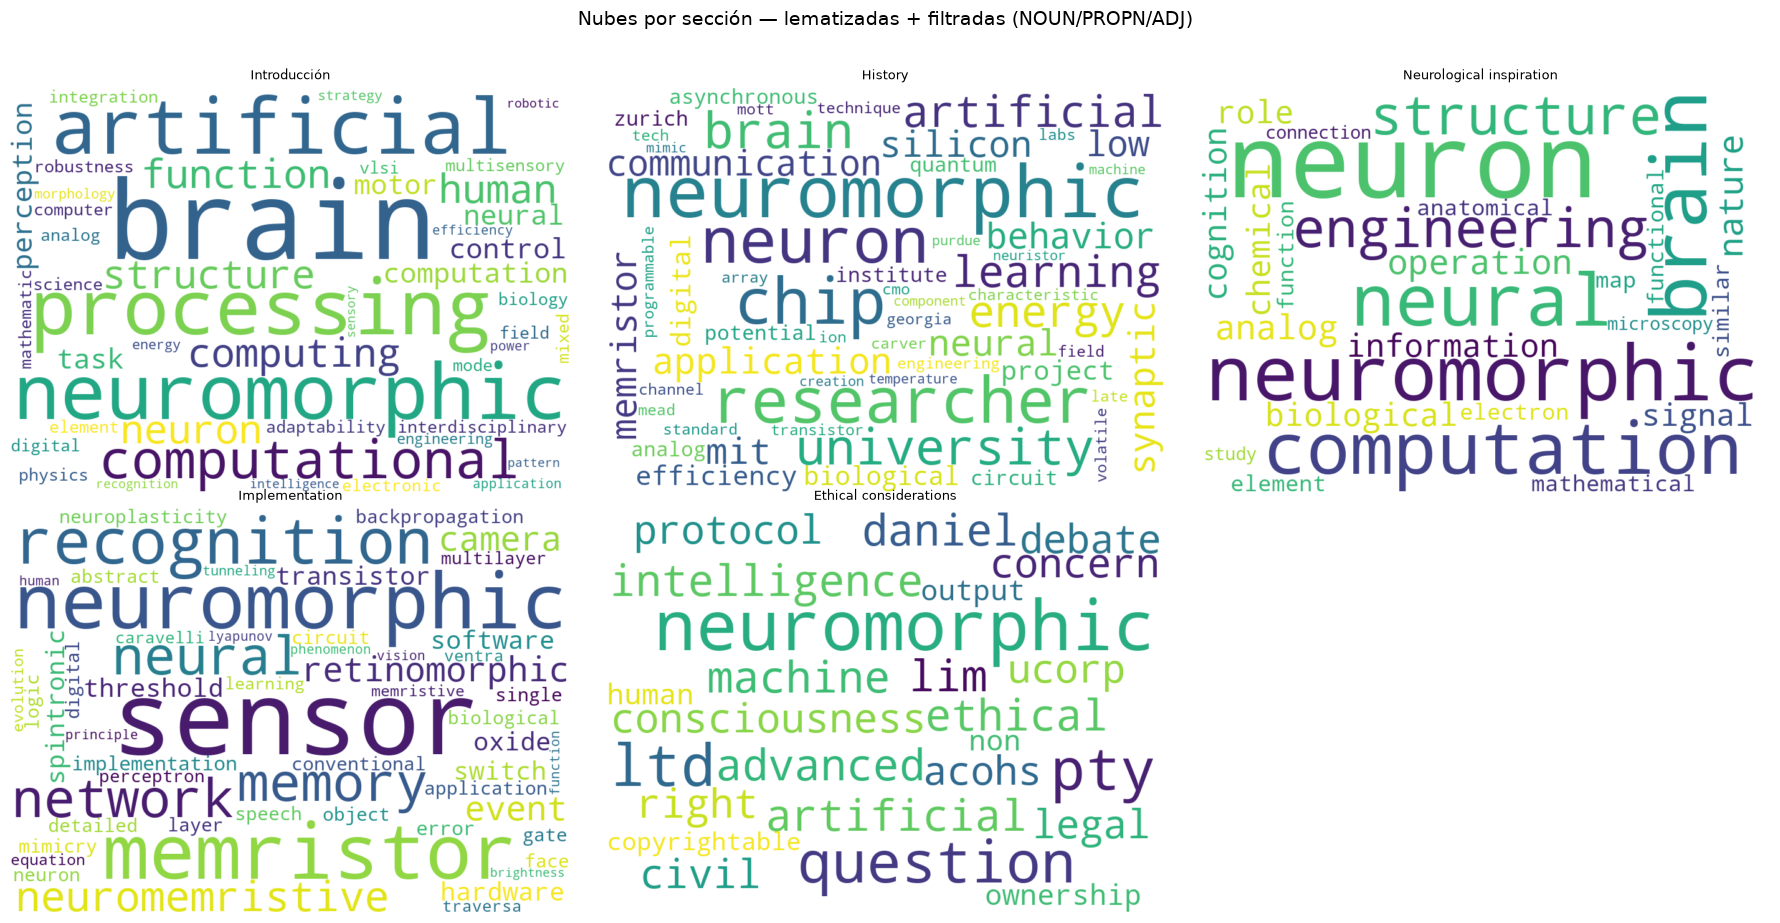

Listo


In [5]:
# -*- coding: utf-8 -*-
import os
import math
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from collections import Counter

os.makedirs('nubes_por_seccion_filtradas', exist_ok=True)

nombres = list(secciones.keys())
cols = math.ceil(math.sqrt(len(nombres))) or 1
rows = math.ceil(len(nombres)/cols) or 1

fig, axes = plt.subplots(rows, cols, figsize=(6*cols, 4.5*rows))
if len(nombres) == 1:
    axes = [axes]
else:
    axes = axes.flatten()

lemmas_por_seccion = {}

for i, nombre in enumerate(nombres):
    texto_sec = secciones[nombre]
    lem_sec = limpiar_y_lemmatizar(texto_sec)
    lemmas_por_seccion[nombre] = lem_sec
    if not lem_sec:
        axes[i].axis('off')
        axes[i].set_title(nombre, fontsize=9)
        continue
    c = Counter(lem_sec)
    wc = WordCloud(width=900, height=650, background_color='white', colormap='viridis', max_words=55, collocations=False)
    wc.generate_from_frequencies(dict(c))
    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].axis('off')
    axes[i].set_title(nombre, fontsize=9)
    safe = ''.join(ch if ch.isalnum() or ch in '-_ ' else '_' for ch in nombre).strip().replace(' ', '_').lower()
    plt.imsave(f'nubes_por_seccion_filtradas/nube_{safe}.png', wc.to_array())
    print(f'Guardado: nubes_por_seccion_filtradas/nube_{safe}.png')

for j in range(i+1, len(axes)):
    axes[j].axis('off')
plt.suptitle('Nubes por sección — lematizadas + filtradas (NOUN/PROPN/ADJ)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('nubes_por_seccion_filtradas/resumen_nubes_por_seccion_filtradas.png', dpi=220, bbox_inches='tight')
plt.show()
print('Listo')


## Paso 6 — TF-IDF por sección

Con frecuencias vemos qué más se repite. Con **TF-IDF** vemos qué **mejor define** cada sección frente al resto.

Usamos unigramas + bigramas para capturar conceptos compuestos como `spiking neuron`, `neural network`, etc.


In [6]:
# -*- coding: utf-8 -*-
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

docs = []
seccion_nombres = []
for nombre in nombres:
    lem_sec = lemmas_por_seccion.get(nombre, [])
    if not lem_sec:
        texto_sec = secciones[nombre]
        lem_sec = limpiar_y_lemmatizar(texto_sec)
    docs.append(' '.join(lem_sec))
    seccion_nombres.append(nombre)

vectorizer = TfidfVectorizer(max_df=0.85, min_df=1, ngram_range=(1,2))
X = vectorizer.fit_transform(docs)
feature_names = vectorizer.get_feature_names_out()

TOP_N = 12
resultados_tfidf = {}
print('TOP TF-IDF por sección (unigramas + bigramas):\n')

for i, nombre in enumerate(seccion_nombres):
    row = X[i].toarray().flatten()
    top_idx = row.argsort()[::-1][:TOP_N]
    pares = []
    for idx in top_idx:
        if row[idx] > 0:
            pares.append((feature_names[idx], round(row[idx], 4)))
    resultados_tfidf[nombre] = pares
    print(f'### {nombre}')
    for term, score in pares:
        print(f'  {term:<40} {score:.4f}')
    print()


TOP TF-IDF por sección (unigramas + bigramas):

### Introducción
  brain                                    0.2059
  processing                               0.2050
  computational                            0.2050
  artificial                               0.1373
  pattern recognition                      0.1025
  pattern                                  0.1025
  recognition sensory                      0.1025
  sensory processing                       0.1025
  sensory                                  0.1025
  neuromorphic computing                   0.1025
  application artificial                   0.1025
  processing element                       0.1025

### History
  researcher                               0.3134
  chip                                     0.3134
  university                               0.1791
  neuron                                   0.1766
  brain                                    0.1199
  energy                                   0.1084
  learning            

## Paso 7 — Guardado + Heatmap TF-IDF

Guardamos el detalle por sección y generamos un heatmap para comparar rápido qué define cada una.


Guardado: tfidf_por_seccion_detalle.csv


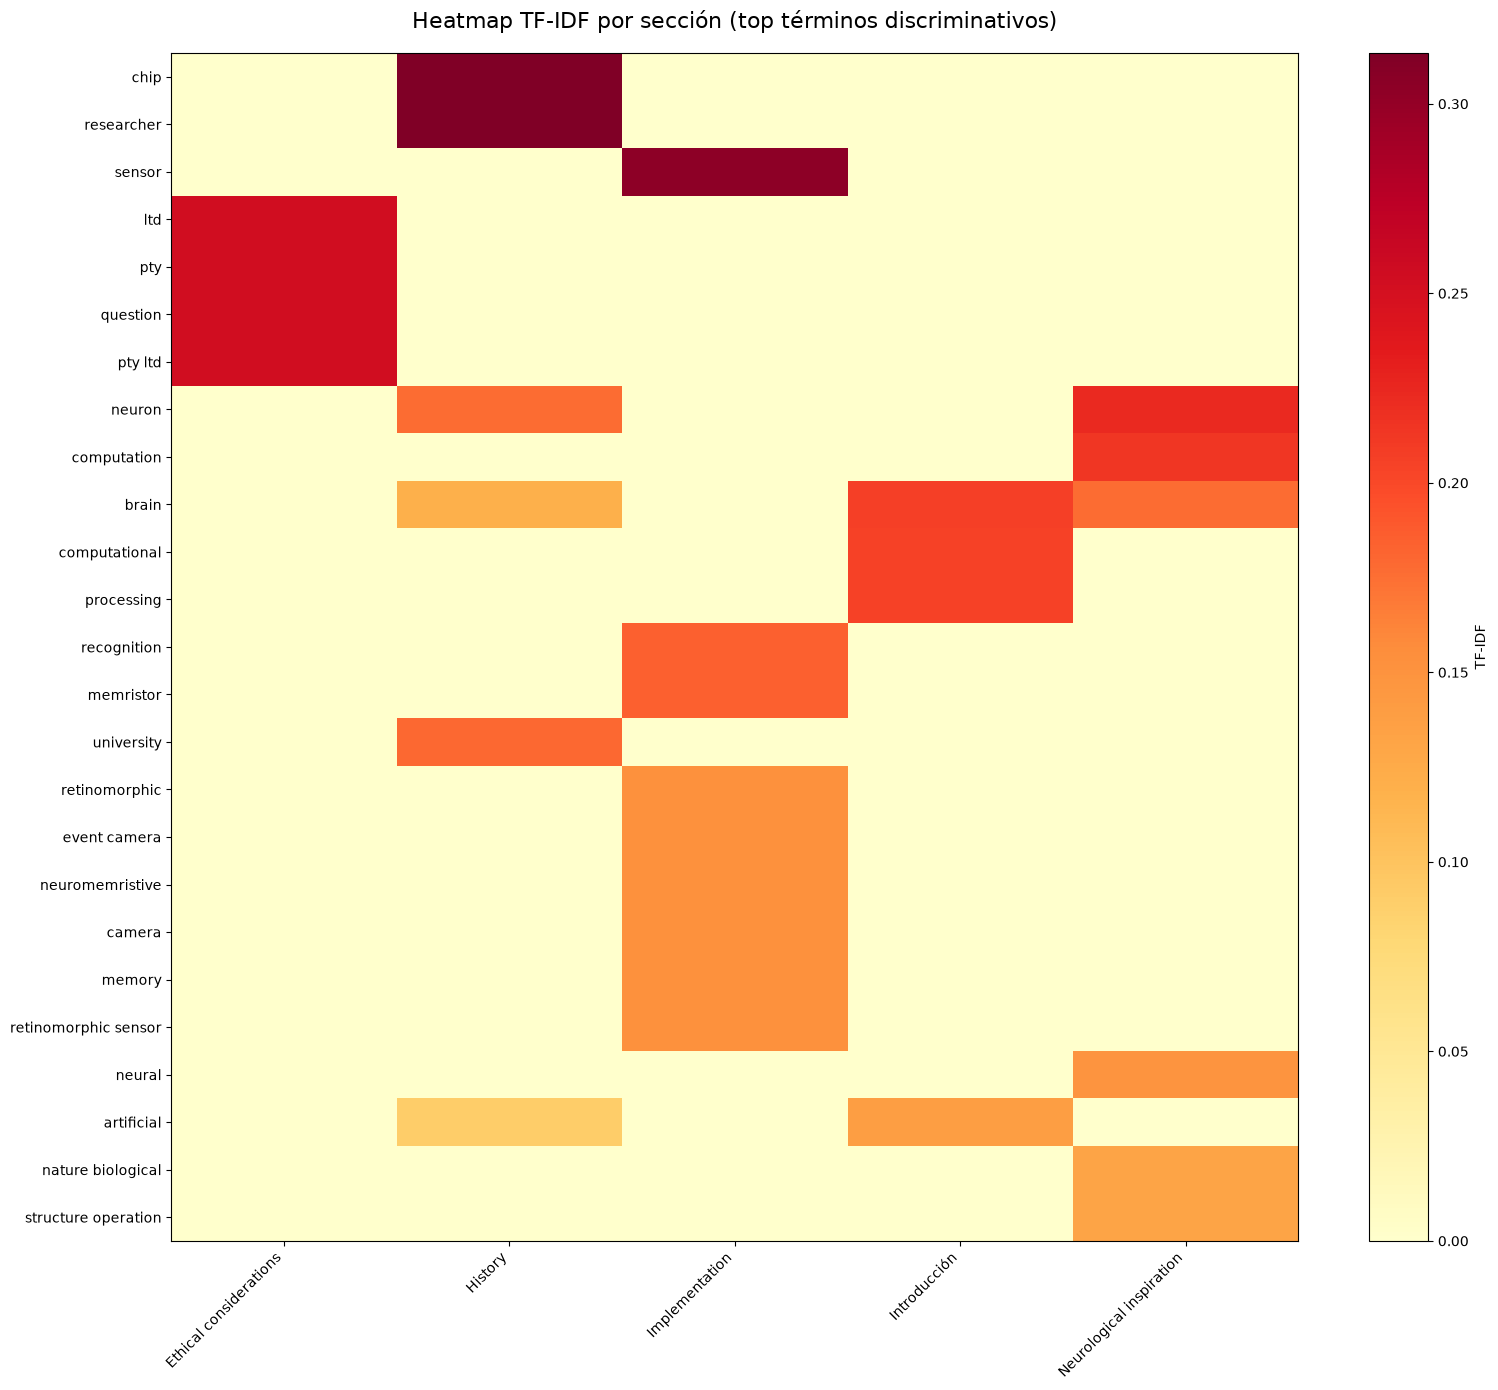

Guardado: heatmap_tfidf_por_seccion.png


seccion,Ethical considerations,History,Implementation,Introducción,Neurological inspiration
termino,,,,,
chip,0.0000,0.3134,0.0000,0.0000,0.0000
researcher,0.0000,0.3134,0.0000,0.0000,0.0000
sensor,0.0000,0.0000,0.3045,0.0000,0.0000
ltd,0.2543,0.0000,0.0000,0.0000,0.0000
pty,0.2543,0.0000,0.0000,0.0000,0.0000
question,0.2543,0.0000,0.0000,0.0000,0.0000
pty ltd,0.2543,0.0000,0.0000,0.0000,0.0000
neuron,0.0000,0.1766,0.0000,0.0000,0.2235
computation,0.0000,0.0000,0.0000,0.0000,0.2134


In [7]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

registros = []
for sec, items in resultados_tfidf.items():
    for term, score in items:
        registros.append({'seccion': sec, 'termino': term, 'tfidf': score})

df_tfidf_detalle = pd.DataFrame(registros)
df_tfidf_detalle.to_csv('tfidf_por_seccion_detalle.csv', index=False)
print('Guardado: tfidf_por_seccion_detalle.csv')

pivot = df_tfidf_detalle.pivot_table(index='termino', columns='seccion', values='tfidf', fill_value=0)
pivot['max_score'] = pivot.max(axis=1)
pivot = pivot.sort_values('max_score', ascending=False).head(25).drop(columns='max_score')

plt.figure(figsize=(16, 14))
im = plt.imshow(pivot.values, aspect='auto', cmap='YlOrRd')
plt.colorbar(im, label='TF-IDF')
plt.xticks(range(len(pivot.columns)), pivot.columns, rotation=45, ha='right')
plt.yticks(range(len(pivot.index)), pivot.index)
plt.title('Heatmap TF-IDF por sección (top términos discriminativos)', fontsize=16, pad=18)
plt.tight_layout()
plt.savefig('heatmap_tfidf_por_seccion.png', dpi=220, bbox_inches='tight')
plt.show()
print('Guardado: heatmap_tfidf_por_seccion.png')
pivot


---
## Archivos generados

- `frecuencias_palabras_lemas.csv` — Frecuencias tras lematizar + filtrar por NOUN/PROPN/ADJ
- `nube_de_palabras_lematizada.png` — Nube global limpia
- `nubes_por_seccion_filtradas/` — Nubes por sección + resumen
- `tfidf_por_seccion_detalle.csv` — Top TF-IDF por sección (1-2 gramos)
- `heatmap_tfidf_por_seccion.png` — Comparativa visual por sección

